# Solution: What drove the heat in London on 13 August 2026?

Solution of **Exercise 6** of `explain_AIFS.ipynb`. It uses the backward sensitivities (adjoint / VJP) of AIFS-CRPS to find which **variables**, **region** and **input time** the London 2t forecast at 18 UTC depended on, on the day when the UK had its hottest day of 2026 (13 August 2026).

- `hw`: heat-wave input state, 13 Aug 2026 12 UTC (the two input steps are 06 and 12 UTC). The forecast is valid at 18 UTC.
- `ref`: reference input state, 19 Aug 2026 12 UTC, an ordinary summer day.
- Target: mean 2t over London (51.5°N, 0.1°W, radius 150 km) at +6 h.

Run this notebook in the environment described in `explain_AIFS.ipynb` (GPU needed). The text of the answers refers to the results obtained with `seed=42`.

In [1]:
import datetime
import os
import warnings
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from helpers import PATCH_METADATA
from helpers import haversine
from helpers import load_ckpt
from helpers import load_input_state
from perturbation import Perturbation
from plotting import plot_sensitivities
from sensitivities import SensitivitiesRunner

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["ANEMOI_INFERENCE_NUM_CHUNKS"] = "16"
warnings.filterwarnings("ignore")

assert torch.cuda.is_available(), "CUDA is not available. Please check your GPU setup."

ckpt = load_ckpt("inference-aifs-crps-o96.ckpt")

PROG = ["2t", "tcw", "t_850", "z_1000", "z_700", "z_500", "z_300", "z_250"]  # prognostic variables
Z_LEVELS = [v for v in PROG if v.startswith("z_")]

## Task 6.1: Load the data and look at the anomalies

The default open-data server only keeps the latest days, so for these past dates we read an archive with `source="google"`.

`LocalPerturbation` is the class of the notebook, with two additions: `normalise=True` puts `1/N` on each of the `N` grid points so that the target is the **mean** over the region, and `region_indices` gives the grid points of the region. Note that the longitude has to be between 0 and 360, so 0.1°W is `359.9`.

In [2]:
class LocalPerturbation(Perturbation):
    """Perturbation class."""

    def __init__(
        self,
        checkpoint: str,
        perturbed_variable: str,
        perturbation_location: float,
        perturbation_radius_km: float = 100.0,
        normalise: bool = False,
        patch_metadata: dict[str, Any] = {},
    ) -> None:
        super().__init__(checkpoint, patch_metadata=patch_metadata)

        assert len(perturbation_location) == 2, "perturbation_location must be a tuple of (lat, lon)"
        assert perturbation_location[0] >= -90 and perturbation_location[0] <= 90, "Latitude must be between -90 and 90"
        assert perturbation_location[1] >= 0 and perturbation_location[1] <= 360, "Longitude must be between 0 and 360"

        self.perturbed_variable = perturbed_variable
        self.perturbation_location = torch.tensor(perturbation_location)
        self.perturbation_radius_km = perturbation_radius_km
        self.normalise = normalise

        # Indices of the grid points within the radius of the location
        dists = haversine(self.coords, self.perturbation_location)
        self.region_indices = torch.where(dists < self.perturbation_radius_km)[0]
        assert len(self.region_indices) > 0, "No grid points found within the specified perturbation radius."

    def create(self, *args, **kwargs) -> torch.Tensor:
        """Get the perturbation data."""
        var_idx = self.variable_to_output_tensor_index[self.perturbed_variable]
        perturbation = torch.zeros(self.output_shape)

        # If normalise=True the perturbation is 1/N on each of the N points, so that the target of the
        # sensitivities is the *mean* of the variable over the region (instead of the sum).
        value = 1.0 / len(self.region_indices) if self.normalise else 1.0
        perturbation[..., self.region_indices, var_idx] = value
        return perturbation

In [3]:
HW_DATE = datetime.datetime(2026, 8, 13, 12)
REF_DATE = datetime.datetime(2026, 8, 19, 12)

hw = load_input_state(HW_DATE, resolution="O96", source="google")
ref = load_input_state(REF_DATE, resolution="O96", source="google")

perturbation = LocalPerturbation(
    ckpt,
    perturbed_variable="2t",
    perturbation_location=(51.5, 359.9),  # London (lat, lon in [0, 360])
    perturbation_radius_km=150.0,
    normalise=True,
    patch_metadata=PATCH_METADATA,
)
idx = perturbation.region_indices.numpy()
lat, lon = perturbation.coords[:, 0].numpy(), perturbation.coords[:, 1].numpy()
print(f"{len(idx)} grid points in the London region")

[data] Patching metadata with {'metadata_inference': {'data': {'timesteps': {'input_relative_date_indices': [0, 1], 'output_relative_date_indices': [2]}}}}


5 grid points in the London region


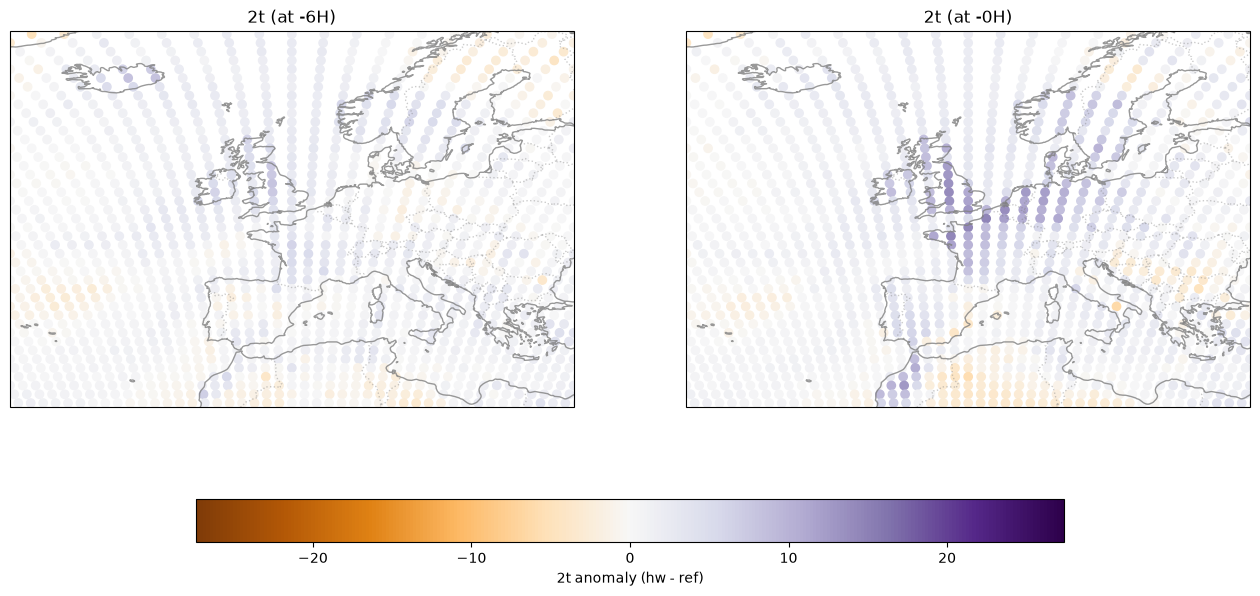

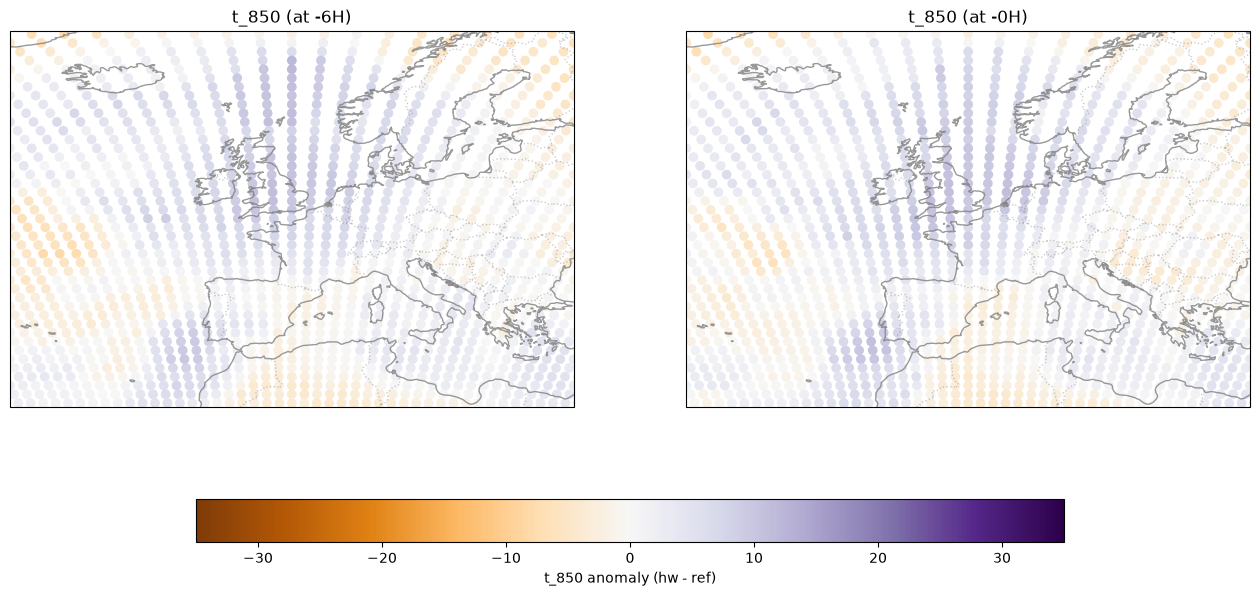

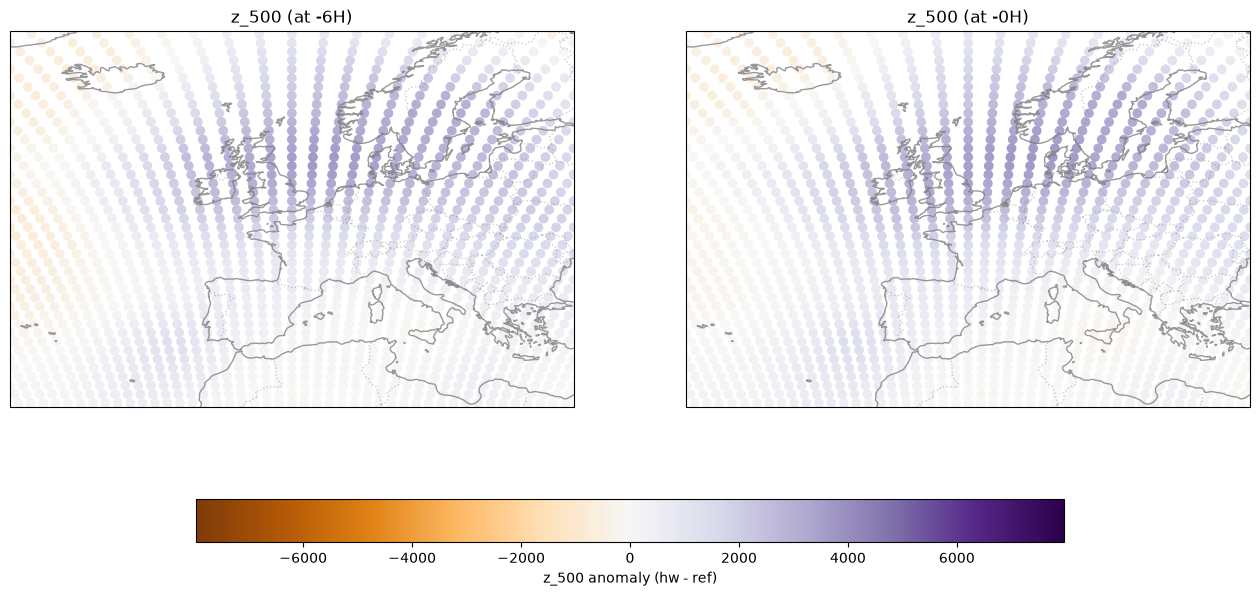

In [4]:
# Anomaly hw - ref of the input state (2 input times: 06 and 12 UTC)
anomaly = {
    "fields": {v: hw["fields"][v] - ref["fields"][v] for v in PROG},
    "latitudes": lat,
    "longitudes": lon,
}

for variable in ["2t", "t_850", "z_500"]:
    plot_sensitivities(anomaly, variable, area=(-30, 30, 30, 70), label="anomaly (hw - ref)")

In [5]:
print("Anomaly hw - ref, mean over the London region at 12 UTC:")
for variable in ["2t", "t_850", "z_500", "tcw"]:
    print(f"  {variable:6s} {anomaly['fields'][variable][1][idx].mean():10.2f}")
print(f"z_500 anomaly in geopotential height: {anomaly['fields']['z_500'][1][idx].mean() / 9.80665:.0f} m")

Anomaly hw - ref, mean over the London region at 12 UTC:
  2t          11.80
  t_850       10.04
  z_500     2927.27
  tcw          2.24
z_500 anomaly in geopotential height: 298 m


**Answer 6.1.** At 12 UTC the hot state is much warmer than the reference over the UK, the Channel and the Low Countries (the 2t anomaly reaches +14.7 K, near the Channel coast of northern France), while at 06 UTC the anomaly is still weaker (at most +8 K): the heat builds up during the morning of 13 August.

Averaged over the London region at 12 UTC the anomalies are **+11.8 K in 2t**, **+10.0 K in `t_850`**, **+2930 m²/s² (≈ +300 m) in `z_500`** and +2.2 kg/m² in `tcw`. The surface and 850 hPa temperatures are warmer by a similar amount, i.e. the whole lower troposphere is warm, and the 500 hPa heights are much higher than on the reference day. This is the signature of a warm air mass under a ridge (a "heat dome") over western Europe. The air is not dry: `tcw` is slightly higher, as expected for warmer air.

## Task 6.2: Compute the sensitivities and the forecasts

The runner works in physical units: the sensitivities are in **K of London 2t at 18 UTC per unit of each input variable**. The forward forecast of the last run is available in `runner.last_prediction`.

In [6]:
runner = SensitivitiesRunner(
    ckpt,
    device="cuda",
    perturb_normalised_space=False,  # the perturbation (1 K, averaged over London) is in physical units
    return_unnormalised_sensitivities=True,  # sensitivities with respect to the physical inputs
    patch_metadata=PATCH_METADATA,
    seed=42,
)

var_2t = perturbation.variable_to_output_tensor_index["2t"]


def run(state):
    """Return the sensitivities and the forecast (mean 2t over London, in degC) for an input state."""
    for sensitivities in runner.run(input_state=state, perturbation=perturbation, lead_time="6h"):
        pass
    forecast = runner.last_prediction[0, 0, idx, var_2t].mean().item() - 273.15
    return {k: v.copy() for k, v in sensitivities["fields"].items()}, forecast


sens_hw, fc_hw = run(hw)
sens_ref, fc_ref = run(ref)

print(f"Forecast 2t over London at 18 UTC: hw = {fc_hw:.2f} degC, ref = {fc_ref:.2f} degC, difference = {fc_hw - fc_ref:.2f} K")
an_hw, an_ref = hw["fields"]["2t"][1][idx].mean() - 273.15, ref["fields"]["2t"][1][idx].mean() - 273.15
print(f"Analysis 2t over London at 12 UTC:  hw = {an_hw:.2f} degC, ref = {an_ref:.2f} degC, difference = {an_hw - an_ref:.2f} K")

[data] Patching metadata with DotDict({'metadata_inference': DotDict({'data': DotDict({'timesteps': DotDict({'input_relative_date_indices': [0, 1], 'output_relative_date_indices': [2]})})})})


[data] Constant forcings are not supported by this runner.


[data] ['lsm', 'sdor', 'slor', 'z'] must be provided in the input state by the user.


Forecast 2t over London at 18 UTC: hw = 31.82 degC, ref = 19.67 degC, difference = 12.15 K
Analysis 2t over London at 12 UTC:  hw = 32.60 degC, ref = 20.81 degC, difference = 11.80 K


**Answer 6.2.** The model forecasts a mean 2t over London of **31.8 °C at 18 UTC for `hw`** and **19.7 °C for `ref`**, a difference of **12.1 K**. This is close to the difference of the 12 UTC analyses (32.6 °C vs 20.8 °C, 11.8 K): the model keeps the strong contrast between the two days during the afternoon.

## Task 6.3: Attribute the forecast difference to the inputs

Contribution (K) = sensitivity (K per unit) x anomaly (units). Only the prognostic variables are used: the anomalies of the static fields are zero, and the computed forcings (insolation, day of the year, ...) differ very little between the two days.

        06 UTC input  12 UTC input
2t              0.32          7.22
tcw             0.09         -0.90
t_850           4.16         -6.53
z_1000          6.94        -13.48
z_700         -15.10         24.43
z_500           0.34          1.61
z_300          -0.09         -6.26
z_250           1.96          2.98
total          -1.38          9.07

First-order attribution: 7.69 K  vs  forecast difference: 12.15 K (63% explained)


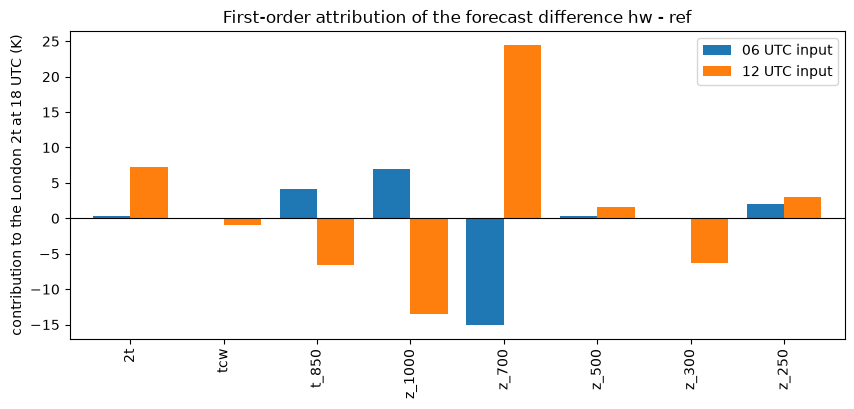

In [7]:
# Contribution of each variable at each grid point, using the sensitivities of the hot state, shape (2 input times, values)
contribution = {v: sens_hw[v] * (hw["fields"][v] - ref["fields"][v]) for v in PROG}
total = sum(contribution.values())

table = pd.DataFrame(
    {"06 UTC input": [contribution[v][0].sum() for v in PROG], "12 UTC input": [contribution[v][1].sum() for v in PROG]},
    index=PROG,
)
table.loc["total"] = table.sum()
print(table.round(2))
print(f"\nFirst-order attribution: {total.sum():.2f} K  vs  forecast difference: {fc_hw - fc_ref:.2f} K "
      f"({100 * total.sum() / (fc_hw - fc_ref):.0f}% explained)")

ax = table.drop("total").plot.bar(figsize=(10, 4), width=0.8)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("contribution to the London 2t at 18 UTC (K)")
ax.set_title("First-order attribution of the forecast difference hw - ref")
plt.show()

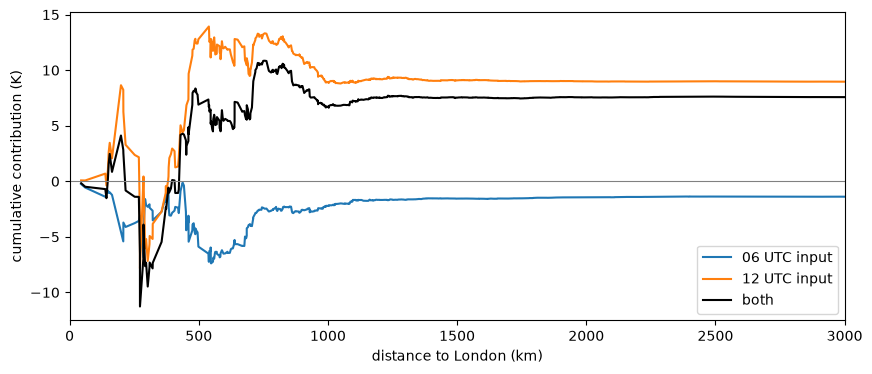

within  200 km:   4.12 K  ( 54% of the total)
within  300 km:  -7.32 K  (-95% of the total)
within  500 km:   6.90 K  ( 90% of the total)
within 1000 km:   6.71 K  ( 87% of the total)
within 2000 km:   7.56 K  ( 98% of the total)


In [8]:
# Cumulative contribution as a function of the distance to London
dist = haversine(perturbation.coords, perturbation.perturbation_location).numpy()
order = np.argsort(dist)

fig, ax = plt.subplots(figsize=(10, 4))
for t, name in enumerate(["06 UTC input", "12 UTC input"]):
    ax.plot(dist[order], np.cumsum(total[t][order]), label=name)
ax.plot(dist[order], np.cumsum(total.sum(axis=0)[order]), "k", label="both")
ax.set_xlim(0, 3000)
ax.set_xlabel("distance to London (km)")
ax.set_ylabel("cumulative contribution (K)")
ax.axhline(0, color="grey", lw=0.8)
ax.legend()
plt.show()

for radius in [200, 300, 500, 1000, 2000]:
    print(f"within {radius:4d} km: {total[:, dist < radius].sum():6.2f} K  ({100 * total[:, dist < radius].sum() / total.sum():3.0f}% of the total)")

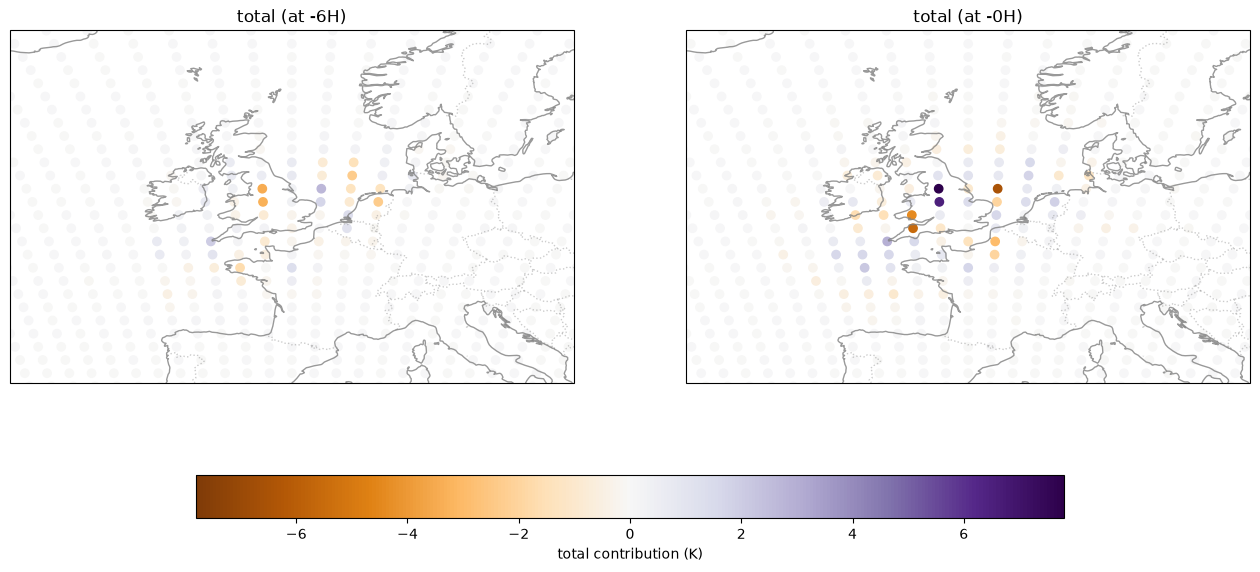

In [9]:
# Map of the total contribution (sum over the variables)
plot_sensitivities(
    {"fields": {"total": total}, "latitudes": lat, "longitudes": lon},
    "total",
    area=(-20, 20, 40, 65),
    label="contribution (K)",
)

**Answer 6.3.** **Which variables and which time.** At the **12 UTC** input, `2t` gives the largest single positive contribution (+7.2 K). The geopotential levels have large contributions of both signs (`z_700` +24.4 K, `z_1000` -13.5 K, `z_300` -6.3 K, `z_250` +3.0 K, `z_500` +1.6 K) and `t_850` is -6.5 K, while `tcw` is small (-0.9 K). The **06 UTC** input also has large terms of both signs (`z_700` -15.1 K, `z_1000` +6.9 K, `t_850` +4.2 K) which almost cancel (total -1.4 K), so the sum is dominated by the latest input time (+9.1 K). Why the two input times have opposite signs is explained in the next section. The total first-order attribution is **7.7 K, i.e. 63% of the 12.1 K** forecast difference.

The big opposite-sign terms of the geopotential levels and of `t_850` are a warning: these inputs are strongly correlated (hydrostatic balance links the geopotential differences between levels to the temperature of the layer), so the model can use them interchangeably and the individual partial derivatives are large and cancel. Only **sums over groups** of variables (and over several grid points) are meaningful; the map of the total contribution also alternates in sign between neighbouring grid points.

**How local.** The cumulative contribution fluctuates strongly in the first ~500 km (large terms of both signs), but it is **flat beyond ~1000 km**: the total changes from 6.7 K within 1000 km to 7.6 K within 2000 km and 7.7 K in total. The forecast at 18 UTC only depends on the inputs close to London. This is expected for a single 6-hour step: the model can only bring information from a limited distance in 6 hours. To trace the **origin** of the hot air mass (e.g. from Iberia or from North Africa) a longer lead time would be needed, by chaining several steps backwards.

### Why do the 06 and 12 UTC contributions have opposite signs?

The model takes **two** snapshots as input: the state at `t-6h` (06 UTC) and at `t` (12 UTC). It is sensitive to each of them, and for `t_850`, `z_1000` and `z_700` the two sensitivities have **opposite signs**. This is not a mistake, and it is not that 06 UTC "cools" and 12 UTC "heats".

**A simple picture.** Imagine a model that predicts by *extrapolating the change* between the two snapshots:

$$\text{forecast} = x_t + a\,(x_t - x_{t-6h}) = (1 + a)\,x_t \; - \; a\,x_{t-6h}$$

With $a = 1.5$ the coefficient on the current state is $+2.5$ and the coefficient on the previous state is $-1.5$: opposite signs, because the model reads the *evolution* from the difference between the two snapshots. A heat wave is a **persistent** anomaly $D$: both snapshots are too warm by about the same amount. Its effect is $2.5 D - 1.5 D = 1.0 D$: two large opposite terms cancel to a smaller net one.

**The exact split.** For any sensitivities $s_{06}, s_{12}$ and anomalies $d_{06}, d_{12}$,

$$s_{06} d_{06} + s_{12} d_{12} \;=\; \underbrace{\tfrac{1}{2}(s_{06} + s_{12})(d_{06} + d_{12})}_{\text{mean part: both times shifted together}} \;+\; \underbrace{\tfrac{1}{2}(s_{12} - s_{06})(d_{12} - d_{06})}_{\text{tendency part: change between the two times}}$$

The mean part is the effect of a persistent anomaly. The tendency part is the effect of a *different evolution* between 06 and 12 UTC.

In [10]:
# Exact split of the first-order attribution into a "mean" and a "tendency" part (K, summed over grid points)
rows = {}
for v in PROG:
    s, d = sens_hw[v], hw["fields"][v] - ref["fields"][v]  # (2 input times, values)
    mean_part = ((s[0] + s[1]) * (d[0] + d[1]) / 2).sum()
    tend_part = ((s[1] - s[0]) * (d[1] - d[0]) / 2).sum()
    c06, c12 = (s[0] * d[0]).sum(), (s[1] * d[1]).sum()
    assert np.isclose(c06 + c12, mean_part + tend_part, rtol=1e-3, atol=1e-3)  # the split is exact
    rows[v] = {
        "06 UTC": c06,
        "12 UTC": c12,
        "sum": c06 + c12,
        "mean part": mean_part,
        "tendency part": tend_part,
        "sens ratio 06/12": s[0].sum() / s[1].sum(),  # ratio of the summed sensitivities of the two times
        "anomaly corr 06-12": np.corrcoef(d[0], d[1])[0, 1],  # how similar the anomalies of the two times are
    }
split = pd.DataFrame(rows).T
split.loc["total", ["06 UTC", "12 UTC", "sum", "mean part", "tendency part"]] = split[
    ["06 UTC", "12 UTC", "sum", "mean part", "tendency part"]
].sum()
print(split.round(2).to_string())

        06 UTC  12 UTC   sum  mean part  tendency part  sens ratio 06/12  anomaly corr 06-12
2t        0.32    7.22  7.54       5.40           2.14              0.19                0.86
tcw       0.09   -0.90 -0.81      -0.77          -0.04             -0.21                0.86
t_850     4.16   -6.53 -2.37      -2.20          -0.17             -0.61                0.91
z_1000    6.94  -13.48 -6.54      -5.32          -1.23             -0.50                0.97
z_700   -15.10   24.43  9.33       7.66           1.67             -0.61                0.98
z_500     0.34    1.61  1.95       2.45          -0.50              0.30                0.98
z_300    -0.09   -6.26 -6.35      -6.04          -0.32             -0.14                0.98
z_250     1.96    2.98  4.94       4.63           0.31              9.75                0.98
total    -1.38    9.07  7.69       5.82           1.87               NaN                 NaN


**Answer.** The attribution is dominated by the **mean part**: of the 7.7 K total, 5.8 K come from the persistent anomaly and only 1.9 K from the change between 06 and 12 UTC. For `z_700` the contributions of the two times are -15.1 K and +24.4 K, but their sum (+9.3 K) is almost all mean part. The anomalies of the two times are almost the same field (correlation 0.86 to 0.98), so the large, opposite terms mostly cancel, like the $2.5 D - 1.5 D$ of the picture. For `t_850`, `z_1000` and `z_700` the summed sensitivity of 06 UTC is about -0.5 to -0.6 times that of 12 UTC (a ratio of $-a/(1+a) = -0.6$ would correspond to $a = 1.5$ in the picture; the real model is of course more complicated). The ratio is not meaningful when the summed sensitivity of 12 UTC is close to zero, as for `z_250`.

`2t` is different: both times have the same sign (the ratio is +0.19) and the 06 UTC input contributes little, so the model relies mostly on the latest `2t`. It is also the variable with the largest tendency part (+2.1 K): the hot day warmed more between 06 and 12 UTC than the reference day.

**What to take from this:** the sign of the 06 UTC contribution alone is not a physical statement (06 UTC does not cool the forecast). It is a property of how the model combines the two snapshots, and for a persistent anomaly such as a heat wave only the sum of the two times is meaningful. The large sensitivity to the *difference* between the two snapshots means the model reads the evolution of the fields, but the hot day and the reference day differ little in this respect, which is why this part is small here. The analysis does not show *why* the network learned this combination.

## Task 6.4: Check the attribution with forward experiments

We replace variables of the heat-wave state `hw` by those of `ref` and look at the change of the forecast. A negative change means that the forecast needed these variables to be hot.

In [11]:
def swap(variables, mask=None, times=(0, 1)):
    """Copy of `hw` where `variables` (at the input `times`, optionally only where `mask`) are replaced by those of `ref`."""
    state = {"date": hw["date"], "fields": {k: v.copy() for k, v in hw["fields"].items()}}
    for v in variables:
        for t in times:
            if mask is None:
                state["fields"][v][t] = ref["fields"][v][t]
            else:
                state["fields"][v][t, mask] = ref["fields"][v][t, mask]
    return state


def change(state):
    """Change of the London forecast (K) with respect to the hot state."""
    return run(state)[1] - fc_hw


experiments = {
    "2t": swap(["2t"]),
    "t_850": swap(["t_850"]),
    "tcw": swap(["tcw"]),
    "all z levels": swap(Z_LEVELS),
    "z_1000 only": swap(["z_1000"]),
    "z_700 only": swap(["z_700"]),
    "z_500 only": swap(["z_500"]),
    "all prognostic variables": swap(PROG),
    "all, within 300 km": swap(PROG, mask=dist < 300),
    "all, outside 300 km": swap(PROG, mask=dist >= 300),
    "all, within 1000 km": swap(PROG, mask=dist < 1000),
    "all, outside 1000 km": swap(PROG, mask=dist >= 1000),
    "all, 12 UTC input only": swap(PROG, times=(1,)),
    "all, 06 UTC input only": swap(PROG, times=(0,)),
}
swaps = pd.Series({name: change(state) for name, state in experiments.items()}, name="forecast change (K)")
print(f"Forecast difference hw - ref: {fc_hw - fc_ref:.2f} K\n")
print(swaps.round(2).to_string())

Forecast difference hw - ref: 12.15 K

2t                          -7.78
t_850                       -3.30
tcw                          0.35
all z levels               -13.15
z_1000 only                 -3.35
z_700 only                 -17.11
z_500 only                 -11.97
all prognostic variables   -12.03
all, within 300 km         -12.21
all, outside 300 km         -2.43
all, within 1000 km        -12.37
all, outside 1000 km        -0.60
all, 12 UTC input only     -13.76
all, 06 UTC input only      -1.20


              first-order attribution  swap experiment
2t                               7.54             7.78
t_850                           -2.37             3.30
tcw                             -0.81            -0.35
all z levels                     3.33            13.15


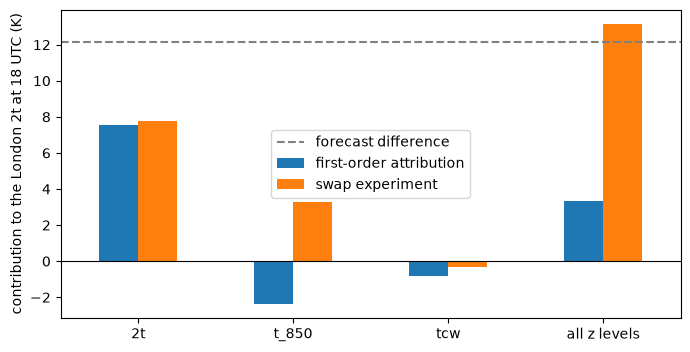

In [12]:
# Compare the first-order attribution (Task 6.3) with the swap experiments (sign flipped: how much hotter than the swapped state)
groups = {"2t": ["2t"], "t_850": ["t_850"], "tcw": ["tcw"], "all z levels": Z_LEVELS}
comparison = pd.DataFrame(
    {
        "first-order attribution": {g: sum(contribution[v].sum() for v in vs) for g, vs in groups.items()},
        "swap experiment": {g: -swaps[g] for g in groups},
    }
)
print(comparison.round(2))
ax = comparison.plot.bar(figsize=(8, 4), rot=0)
ax.axhline(0, color="k", lw=0.8)
ax.axhline(fc_hw - fc_ref, color="grey", ls="--", label="forecast difference")
ax.set_ylabel("contribution to the London 2t at 18 UTC (K)")
ax.legend()
plt.show()

**Answer 6.4.** **Where.** Replacing all the prognostic variables by the `ref` values within 300 km of London reduces the forecast by **-12.2 K**, i.e. the whole difference (-12.1 K), whereas replacing them *outside* 300 km only changes it by -2.4 K and *outside 1000 km* by only -0.6 K. This agrees with Task 6.3 (nothing beyond ~1000 km) and is cleaner, as the swap experiment has no cancellation problem.

**When.** Swapping only the 12 UTC input gives -13.8 K, and only the 06 UTC input gives -1.2 K: the forecast is controlled by the latest input time and the earlier one adds about 1 K. This agrees with the attribution (the 12 UTC input dominates). The two do not add up exactly because the model is not linear.

**Which variables.** `2t` alone gives -7.8 K, in good agreement with its first-order attribution (+7.5 K). `tcw` has a negligible effect (+0.4 K, the attribution is also small, -0.8 K): moisture is not a driver. For `t_850` the two methods **disagree**: replacing it reduces the forecast by 3.3 K, but its first-order attribution is *negative* (-2.4 K). This is the collinearity problem: with `2t` and the geopotential unchanged, the local derivative with respect to `t_850` says little about what happens when `t_850` is changed by 10 K.

**Geopotential.** Replacing all the `z_*` levels gives -13.2 K (more than the total difference, versus +3.3 K for the first-order attribution) and replacing a single level gives -17.1 K for `z_700`, -12.0 K for `z_500` and -3.4 K for `z_1000`. They do not add up and a single one can be larger than the total difference: replacing one level changes the thickness of the layers below and above it, and creates a physically inconsistent atmosphere (hydrostatic balance is broken) for which the model gives an exaggerated response. The model reads the temperature of the column through the geopotential thickness, so one-at-a-time swaps of single levels are not interpretable. Finally, replacing **all** the prognostic variables gives -12.0 K, i.e. it reproduces the `ref` forecast (19.8 °C versus 19.7 °C; the remaining difference comes from the forcings, which are not swapped).

## Task 6.5: Summary of the drivers

**According to AIFS-CRPS, the London temperature of ~32 °C at 18 UTC on 13 August 2026 is the continuation of a warm air mass already in place at 12 UTC close to London.** The forecast is controlled by the **12 UTC input** (the 06 UTC input adds about 1 K) within **a few hundred km of London** (nothing beyond ~1000 km matters), and by the **temperature of the lower troposphere**: `2t` alone is worth about 8 K of the 12 K difference, and `t_850` and the geopotential (thickness) of the layers carry the rest of the warmth in a way that cannot be separated variable by variable. **Moisture is not a driver** (`tcw` changes the forecast by less than 1 K).

What this analysis cannot tell:
- the lead time is a single 6-hour step, so we only see the **immediate** drivers. To find where the hot air came from we would have to chain several steps backwards in time (for instance with a custom `Perturbation` built from the sensitivities of the previous step).
- the sensitivities describe the **model**, learned from correlations in the training data, and not necessarily physical causes. Strongly correlated inputs (`z` levels, `t_850` and `2t`) cannot be separated, and one-at-a-time swaps create unphysical states.
- the model is an ensemble model with noise: the result is for **one member** (see the bonus). The swap experiments are more robust than the first-order attribution, but they should also be checked with several seeds.

### Bonus: robustness to the noise of the ensemble model

In [13]:
rows = []
for seed in [1, 2, 3, 4, 5]:
    runner.noise_seed = seed
    s_hw, f_hw = run(hw)
    s_ref, f_ref = run(ref)
    rows.append(
        {
            "seed": seed,
            "forecast hw (degC)": f_hw,
            "forecast ref (degC)": f_ref,
            "difference (K)": f_hw - f_ref,
            "attribution (K)": sum((s_hw[v] * (hw["fields"][v] - ref["fields"][v])).sum() for v in PROG),
        }
    )
runner.noise_seed = 42
seeds = pd.DataFrame(rows).set_index("seed")
print(seeds.round(2))
print(seeds.agg(["mean", "std"]).round(2))

      forecast hw (degC)  forecast ref (degC)  difference (K)  attribution (K)
seed                                                                          
1                  30.63                19.76           10.87             5.62
2                  31.23                19.98           11.26            10.29
3                  31.05                19.30           11.75             8.18
4                  30.85                19.75           11.11             5.78
5                  31.97                20.25           11.73            10.70
      forecast hw (degC)  forecast ref (degC)  difference (K)  attribution (K)
mean               31.15                19.81           11.34             8.11
std                 0.51                 0.35            0.39             2.40


**Answer (bonus).** With 5 other seeds the forecast contrast is robust: the forecast for `hw` is 31.2 ± 0.5 °C, for `ref` 19.8 ± 0.4 °C and the difference **11.3 ± 0.4 K**. But the **first-order attribution is not**: it ranges from 5.6 K to 10.7 K (8.1 ± 2.4 K). The "63% explained" of seed 42 is therefore not a meaningful number: with another noise realisation the model is linearised at a different point and the large, cancelling terms of the correlated variables change. This is another reason to confirm a gradient-based attribution with forward experiments, and to use several seeds.